<a href="https://colab.research.google.com/github/Makande340/A04-clustering/blob/main/notebook(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mofeoluwa Akande

**Date:** [To be provided]

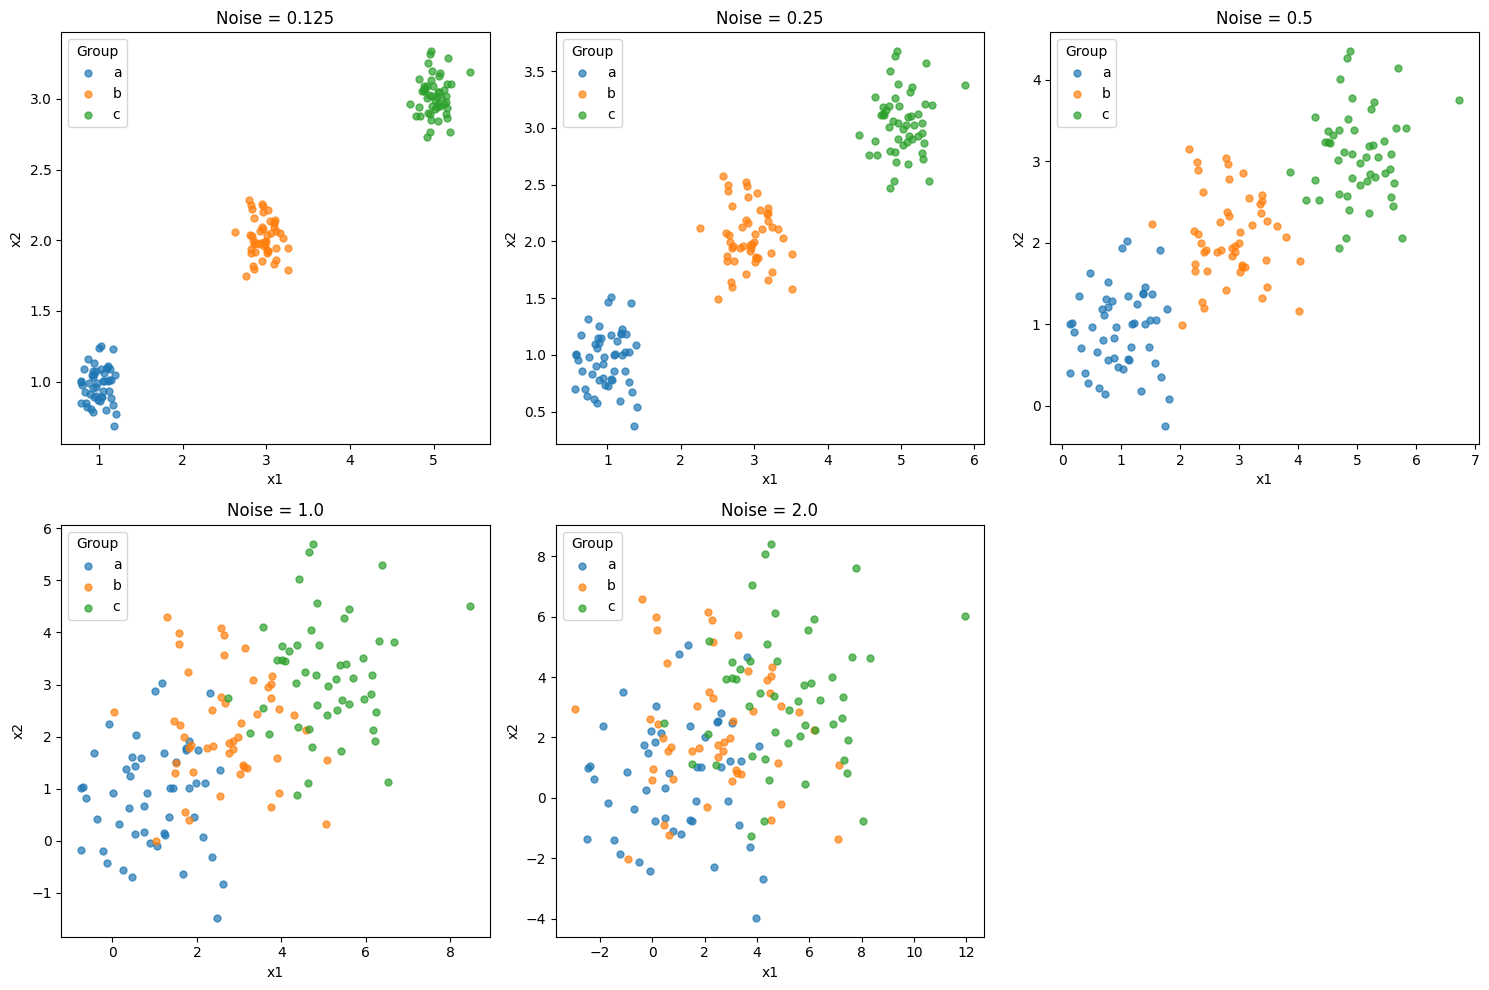

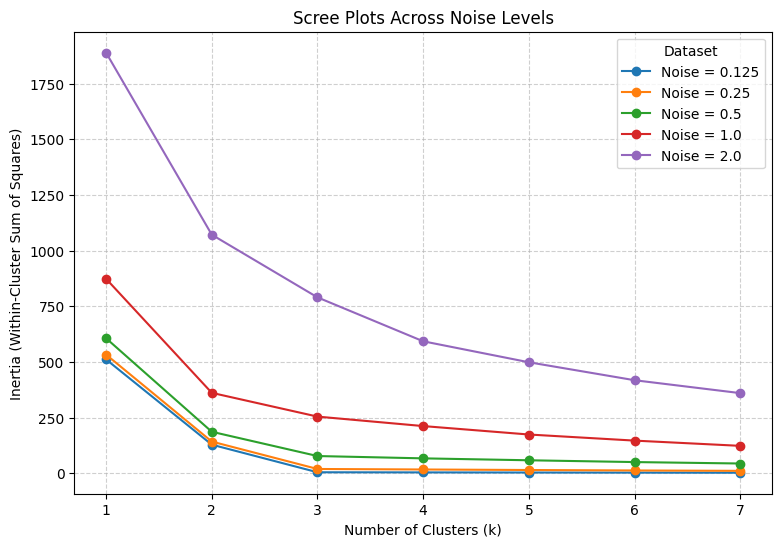

In [7]:
#Q1.1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


#Q1.2


#As the overall noise parameters have a tendency to increase from 0.125 to 2.0, this  will cause the overall visual distinctness to decrease and cause an overlapping effect.


datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, (name, df) in enumerate(datasets.items()):
    ax = axes[i]

    for group in ['a', 'b', 'c']:
        subset = df[df['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7, s=25)

    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_title(name)
    ax.legend(title='Group')

axes[5].set_visible(False)

plt.tight_layout()
plt.show()


#Q1.3

#High levels of noise effects ones ability to not witness any random variation and overlap between data points.
# Noise does not have clear natural groupinfs, so inflation of the variance is a result at higher cluster counts.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

datasets = {
    'Noise = 0.125': df0_125,
    'Noise = 0.25': df0_25,
    'Noise = 0.5': df0_5,
    'Noise = 1.0': df1_0,
    'Noise = 2.0': df2_0
}

k_range = range(1, 8)
plt.figure(figsize=(9, 6))

for name, df in datasets.items():
    X = df[['x1', 'x2']]

    inertias = []
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)

    plt.plot(k_range, inertias, marker='o', label=name)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Scree Plots Across Noise Levels')
plt.legend(title='Dataset')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



#Q1.4

#Intuition of the elbow, is  essentially structured on the backbone of error reduction and model complexiity, where an increase of number of clusters results in error decreasing because data points get scattered in get closer to their assignments
#A sharp drop essentially shows how clusters being added to the






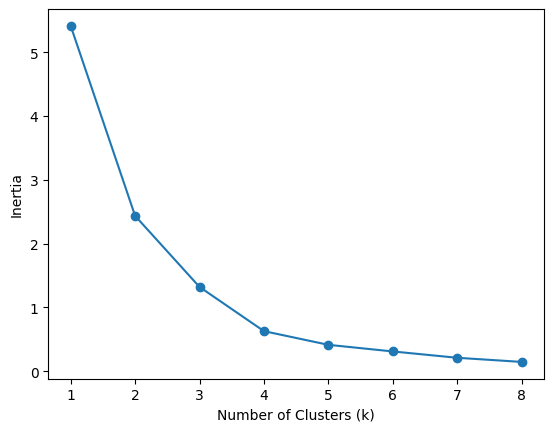

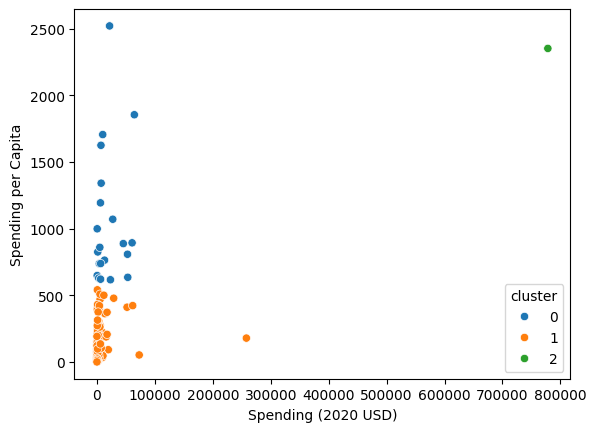

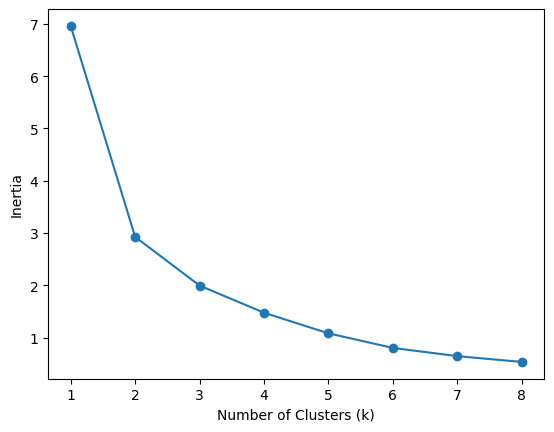

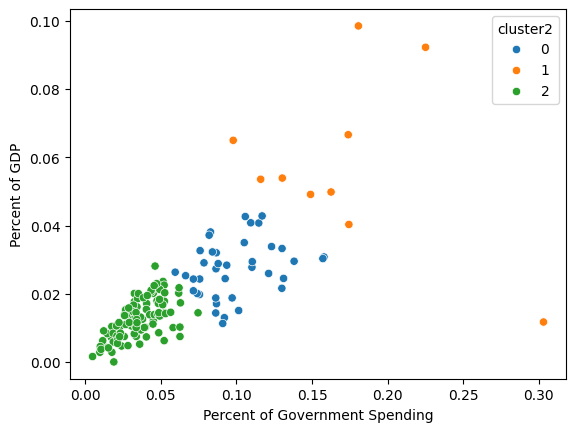

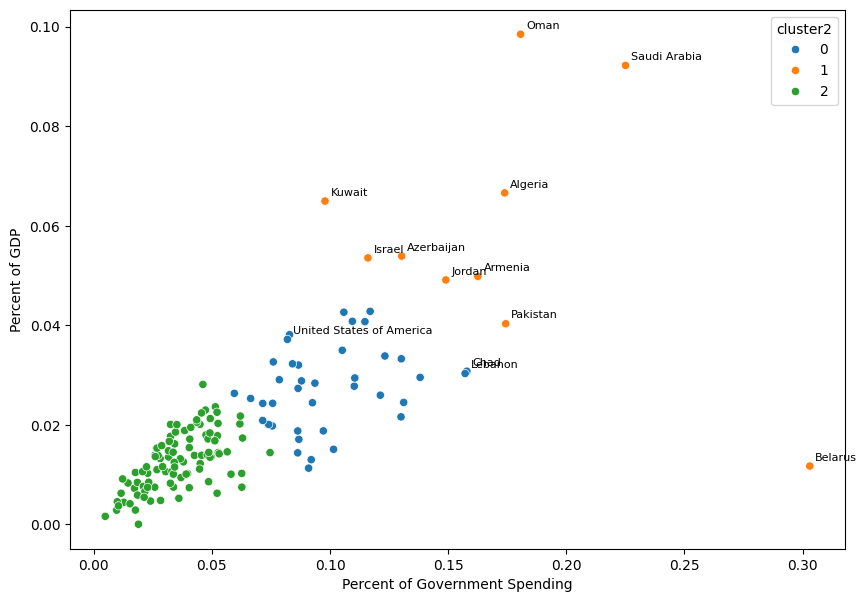

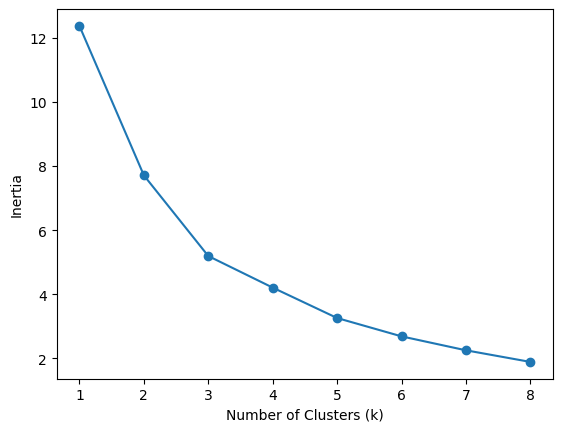

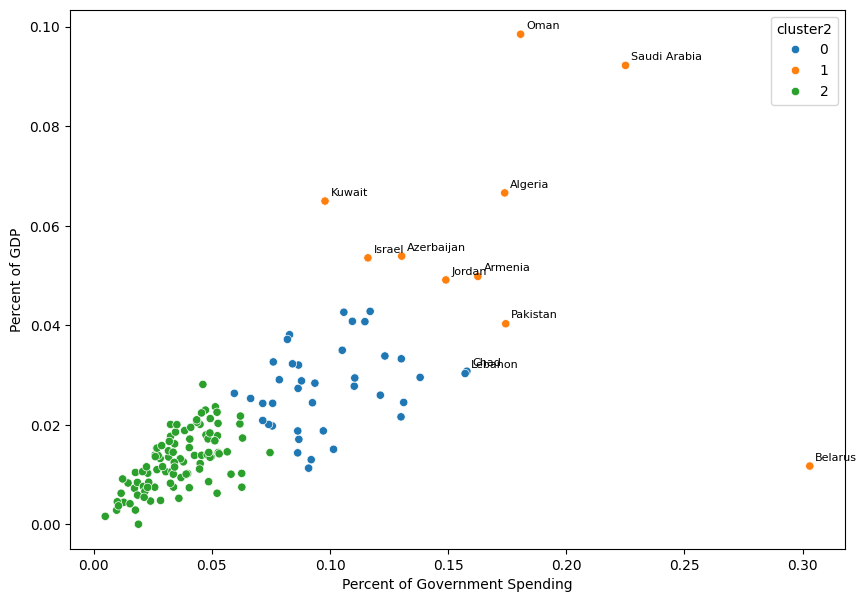

In [9]:

#Q2.1

import pandas as pd
url = "./data/SIPRI Military Expenditure Database.csv"
df = pd.read_csv(url)

df = df[df['Year'] == 2020].dropna()
df = df.drop(columns=['index', 'Year']).set_index('Country')

#After dropping rows with missing values and only taking values at 2020, I also noticed index and yeat can be dropped because neither are real variables.
#Also made country a row label moving out of features.

#Q2.2

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

cols = ['Spending (2020 USD)', 'Spending per Capita']

# min-max normalize
X = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())

# scree plot
ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km = KMeans(3, n_init=10, random_state=0).fit(X)
df['cluster'] = km.labels_

# scatter plot
sns.scatterplot(data=df, x=cols[0], y=cols[1], hue='cluster', palette='tab10')
plt.show()

df.groupby('cluster')[cols].describe()

df.loc['United States of America']

def labeled_scatter(df, xcol, ycol, cluster_col, extra=None, n=8):
    plt.figure(figsize=(10, 7))
    sns.scatterplot(data=df, x=xcol, y=ycol, hue=cluster_col, palette='tab10')

    names = set(df.nlargest(n, xcol).index) | set(df.nlargest(n, ycol).index)
    names |= set(extra or [])

    for name in names:
        plt.annotate(name, (df.loc[name, xcol], df.loc[name, ycol]),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
    plt.show()

#I see as K equal 3 that the cluster is put into the more bigg spenders, the rest of the pack, and the united states isolated on its own level
#The US is alone because its total spending is levels above any other country, the gap between US  (second largest) is rather substantial
#Patterns noticed: Per capita is key indicator of seperation between rich and high spendingg countries
#Pattern of cluster sizes are rather unbalances as the majority of countries are in one cluster with the US being in a league of their own.


#Q2.3

cols2 = ['Percent of Government Spending', 'Percent of GDP']
X2 = (df[cols2] - df[cols2].min()) / (df[cols2].max() - df[cols2].min())

ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X2).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km2 = KMeans(3, n_init=10, random_state=0).fit(X2)
df['cluster2'] = km2.labels_

sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster2', palette='tab10')
plt.show()

df.groupby('cluster2')[cols2].describe()
df.loc['United States of America', 'cluster2']

labeled_scatter(df, cols2[0], cols2[1], 'cluster2',
                extra=['United States of America'])

#It seems like now the US is not an outlier, but now it is in the middle cluster
#Clusters have more balances versus the lopsided numbers in previous distribution
#Different set of countries stand out for different reasons such as conflict and military expenses

#Q2.4

cols4 = ['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']
X4 = (df[cols4] - df[cols4].min()) / (df[cols4].max() - df[cols4].min())

ks = range(1, 9)
inertias = [KMeans(k, n_init=10, random_state=0).fit(X4).inertia_ for k in ks]
plt.plot(ks, inertias, marker='o')
plt.xlabel('Number of Clusters (k)'); plt.ylabel('Inertia')
plt.show()

km4 = KMeans(3, n_init=10, random_state=0).fit(X4)
df['cluster4'] = km4.labels_

df.groupby('cluster4')[cols4].mean()
df['cluster4'].value_counts()
df.loc['United States of America', 'cluster4']

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster2', palette='tab10')

extreme = pd.concat([
    df.nlargest(8, cols2[0]),
    df.nlargest(8, cols2[1]),
]).drop_duplicates()

for name, row in extreme.iterrows():
    plt.annotate(name, (row[cols2[0]], row[cols2[1]]),
                 xytext=(4, 4), textcoords='offset points', fontsize=8)

plt.show()

#In comparison with above, the US is back in a cluster with other countries. Grouped with countries that have high numbers in the two metrics being measured above.
#Seems like the clusters as a whole now mix the two metrics above. Some countries where one metric outweighs the other will cause a drop.
#Q2.5
#Helpful based on what variables were being assessed and utilized, like dollar variables or percent variables allowing for real structure to follow through.
#Limitations came when tackling outliers like US.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]